In [1]:
# Set paths

from pathlib import Path
home = Path.home()
shared = Path('/home/shared/owner')
cop = shared/'CoP_files'
root = cop/'input/CF6_IORSIM_AH/CF6_IORSIM'
#root = cop/'input/CF6_IORSIM_NX40/CF6_IORSIM'


In [2]:
# Run simulation

from ior2ecl import runsim
iorexe = home/'github/IORSim/build/bin/IORSimX'
# IX
runsim(root=root, iorexe=iorexe, only_host=True, intersect=1, nproc=1, nice=19, delete=False);
# IX + IORSim
#runsim(root=root, iorexe=iorexe, intersect=1);
# IORSim
#runsim(root=root, iorexe=iorexe, only_iorsim=True, intersect=1);


    Case      : CF6_IORSIM
    Mode      : Intersect
    Days      : 10.814583333333333
    Run-dir   : /home/AD.NORCERESEARCH.NO/javi/github/IORSim_GUI
    Case-dir  : /home/shared/owner/CoP_files/input/CF6_IORSIM_AH
    Log-files : /home/shared/owner/CoP_files/input/CF6_IORSIM_AH/intersect.log
              : /home/shared/owner/CoP_files/input/CF6_IORSIM_AH/ior2ecl.log
    Version   : 3.7.3
    Started   : 2025-02-18 13:51:33


   Simulation complete, run-time was 0:00:13                                        



In [8]:
# Define core-data functions

from collections import namedtuple
from numpy import pi, diff, cumsum, array, zeros, interp
from pandas import DataFrame, read_csv
from IORlib.utils import Progress
from ior2ecl import IORSim_output
from IORlib.ECL import UNSMRY_file
from pyGeoChem import io_cpp_solver
from pyGeoChem.io_cpp_solver.run import run_simulator

stb2m3 = 1.0 / 6.289811                # 0.158987294928 m3
stb_day2cm3_hour = stb2m3 * 1e6 / 24   # 1 m3 = 1e6 cm3

# Core metrics
dia = 3.8  # cm
L = 22.4   # cm
porosity = 0.4
vol = L * pi * (0.5*dia)**2  # cm^3
porvol = porosity * vol      # cm^3

def core_data(root, path='.'):
    """
    Calculate core simulation data. 
    Return production and injection rates, injected pore-volumes, and 
    species concentrations as numpy arrays.
    """
    # IX data
    # Read water- and oil-production rates from UNSMRY-file
    smry = UNSMRY_file(root)
    ix = smry.welldata(wells=('Prod_Com',), keys=('WWPR', 'WOPR'), named=True, as_array=True)
    # Convert rate to cm3/hour
    watrate = ix.WWPR.Prod_Com * stb_day2cm3_hour
    oilrate = ix.WOPR.Prod_Com * stb_day2cm3_hour
    # Water injection rate is the sum of water and oil production rates
    injrate = watrate + oilrate
    # PV for IX
    dt = diff(ix.days)*24  # timestep in hours
    PV_ix = zeros(len(ix.days))
    PV_ix[1:] = cumsum(injrate[1:]*dt)/porvol

    # IORSim data
    # Read specie data from IORSim output
    ior = IORSim_output(root).welldata('Prod_Com', path=path)
    # IX and IORSim data arrays may have different report steps. Hence, PV for IORSim is 
    # calculated by interpolating on the water-injection rate from IX
    ior_injrate = interp(ior.days, ix.days, injrate)
    dt = diff(ior.days)*24 
    PV_ior = zeros(len(ior.days))
    PV_ior[1:] = cumsum(ior_injrate[1:]*dt)/porvol
    rates = namedtuple('Rates', 'water oil inject PV days dates')(watrate, oilrate, injrate, PV_ix, ix.days, ix.dates)
    species = namedtuple('Species', 'conc prod PV days dates')(ior.conc, ior.prod, PV_ior, ior.days, ior.dates)
    return namedtuple('Core', 'rates species')(rates, species)

def pH_at_temp(dataframe:DataFrame, temp=25, progress:Progress=None, echo=True):
    input_file = 'pH_25deg'
    geo_solver = io_cpp_solver.writer.Input(input_file)
    geo_solver.set_temp(temp)
    species = [name for name in dataframe.columns if name not in ('days', 'pH')]
    pHs = []
    for index,row in dataframe.iterrows():
        if progress:
            progress.print()
        for specie in species:
            geo_solver.add_aq(specie, row[specie])
        geo_solver.write_run_file()
        run_simulator(input_file=input_file+'.dat', echo=echo)
        df_aq = read_csv(input_file+'_aq.out', sep='\t')
        #print('--- H+ ---', index, -df_aq[df_aq['name']=='H+']['log_a'])
        #df_buf = read_csv(input_file+'_aq.out', sep='\t')
        pH = -df_aq[df_aq['name']=='H+']['log_a'].array
        pHs.append(pH[0])
    return pHs

Saved /home/shared/owner/CoP_files/input/CF6_IORSIM_AH/plots/plot_NA.pdf
Saved /home/shared/owner/CoP_files/input/CF6_IORSIM_AH/plots/plot_K.pdf
Saved /home/shared/owner/CoP_files/input/CF6_IORSIM_AH/plots/plot_CA.pdf
Saved /home/shared/owner/CoP_files/input/CF6_IORSIM_AH/plots/plot_MG.pdf
Saved /home/shared/owner/CoP_files/input/CF6_IORSIM_AH/plots/plot_CL.pdf
Saved /home/shared/owner/CoP_files/input/CF6_IORSIM_AH/plots/plot_SO4.pdf
Saved /home/shared/owner/CoP_files/input/CF6_IORSIM_AH/plots/plot_HCO3.pdf
Saved /home/shared/owner/CoP_files/input/CF6_IORSIM_AH/plots/plot_pH.pdf


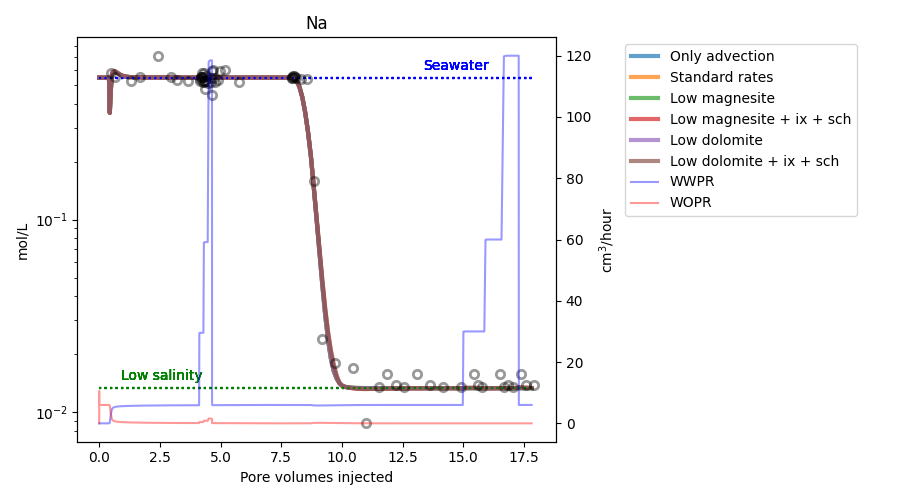

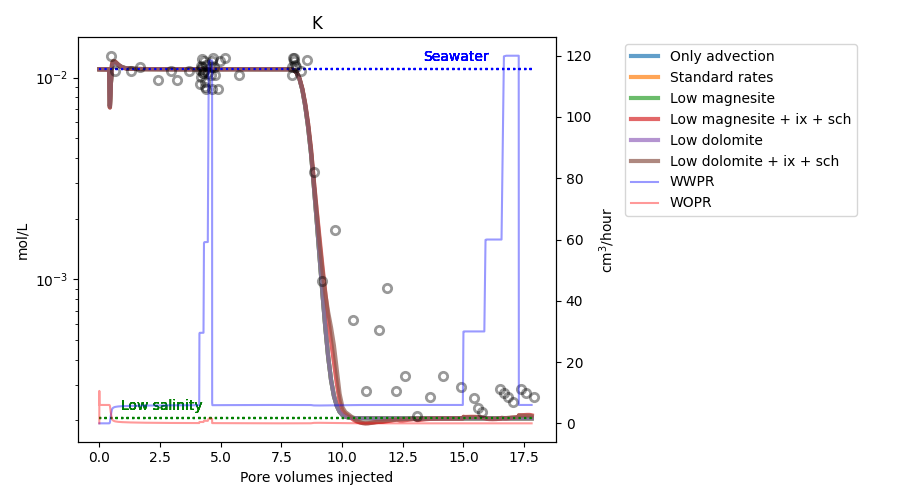

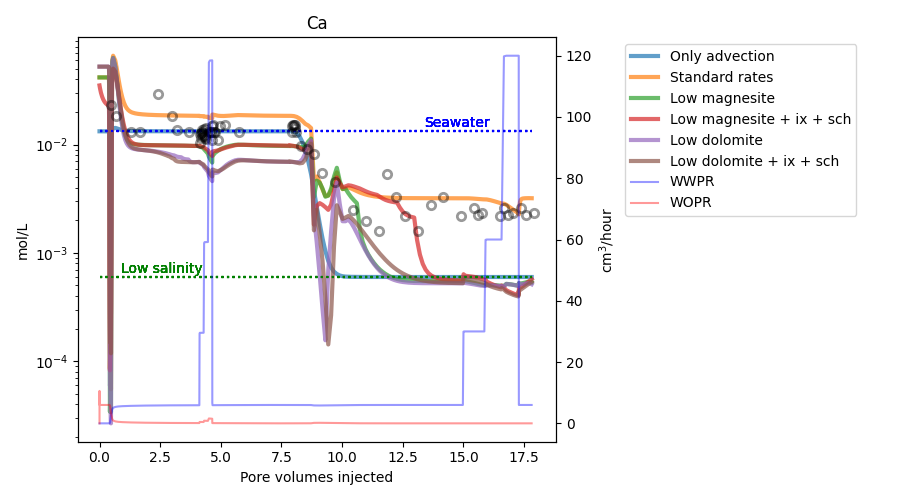

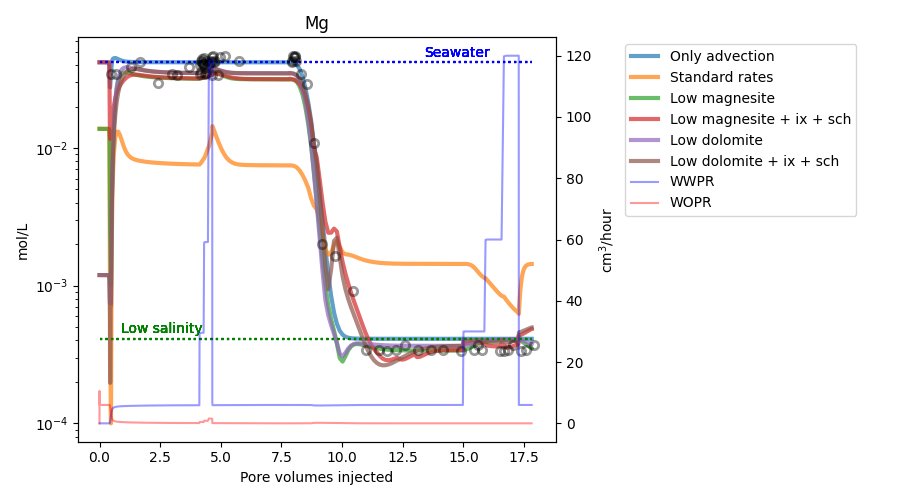

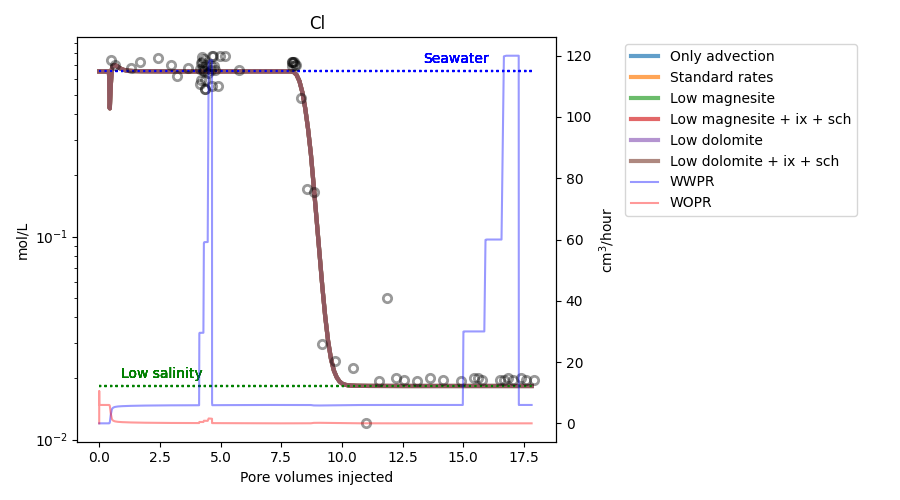

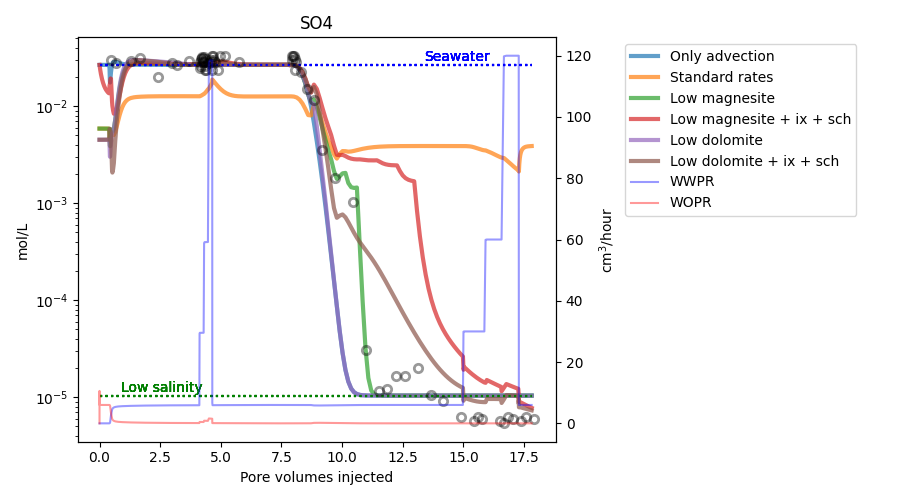

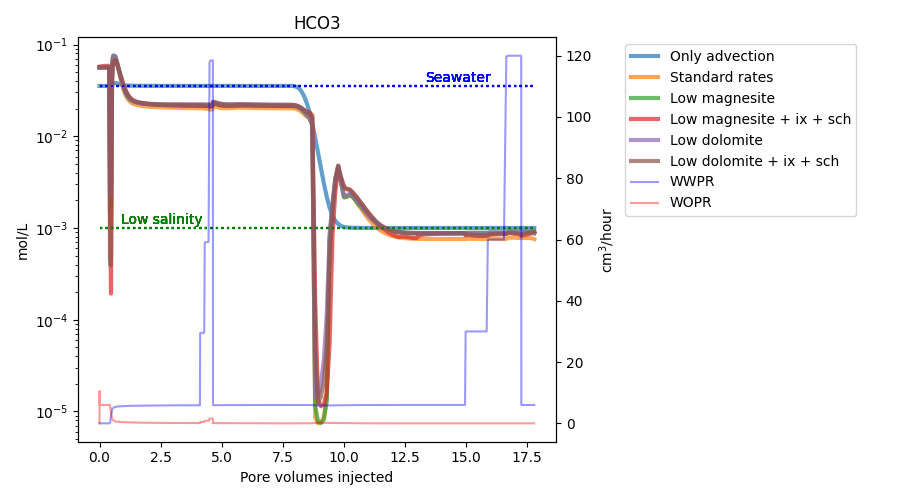

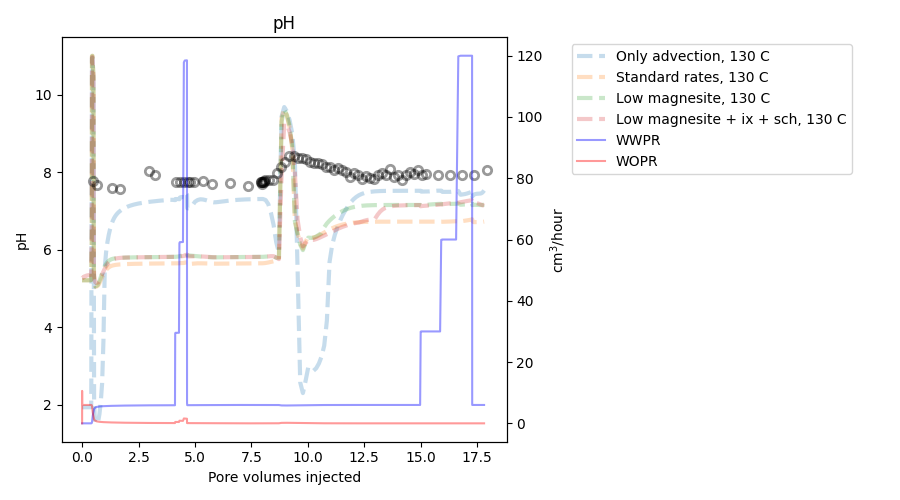

In [9]:
# Plot concentrations

from copy import copy
from itertools import batched
import matplotlib.pyplot as pl
from numpy import log, ones
from IORlib.ECL import UNRST_file
from IORlib.utils import molL2ppm, ppm2molL
from ior2ecl import IORSim_input
from pandas import ExcelFile, read_excel

calc_pH = False
group_on_sim = False

#width = 9 #10
unit = 'molL' #'ppm'

root = cop/'input/CF6_IORSIM_AH/CF6_IORSIM'

#unrst = UNRST_file(root)
iorinp = IORSim_input(root)
#inp_solution = {sol[0]:{k:v for k,v in batched(sol[1:], 2)} for sol in iorinp.get('solution')}
inp_solution = {sol[0]:dict(batched(sol[1:], 2)) for sol in iorinp.get('solution')}

# Read measured ion concentrations from excel-file
#xls = ExcelFile(Path.home()/'github/IORSim/cases/CF6_IORSIM_AH/CF6_ions_v2.xlsx')
xls = ExcelFile(root.with_name('CF6_ions_v2.xlsx'))
ions = read_excel(xls, sheet_name='ions')
#ions_comb = read_excel(xls, sheet_name='ions-combined')
#ions_ior = read_excel(xls, sheet_name='ions-IORSim')

def saveplot(name, echo=True, **kwargs):
    savename = root.parent/name
    pl.savefig(savename, **kwargs) #, dpi=300)
    if echo:
        print(f'Saved {savename}')

def plot_specie(data, specie, handle:list, *args, kind='conc', yaxis='log', width=9, height=5, A=('Seawater', 'b'), B=('Low salinity', 'g'), **kwargs):
    plot_func = pl.plot
    if yaxis == 'log':
        plot_func = pl.semilogy
    pv = data.species.PV
    lw = kwargs.pop('lw', None) or 3
    alpha = kwargs.pop('alpha', None) or 0.7
    values = array(getattr(data.species, kind)[specie.upper()])
    if unit == 'ppm':
        values *= molL2ppm(specie)
    p, = plot_func(pv, values, *args, lw=lw, mfc='None', ms=3, alpha=alpha, **kwargs)
    fig = pl.gcf()
    fig.set_figwidth(width)
    fig.set_figheight(height)
    pl.xlabel('Pore volumes injected')
    pl.ylabel('mol/L')
    if unit == 'ppm':
        pl.ylabel('PPM')
    x = pv[::len(pv)-1]
    y = ones(2)
    if unit == 'ppm':
        y *= molL2ppm(specie)
    ssw = inp_solution['SOLA'][specie] * y
    ls = inp_solution['SOLB'][specie] * y
    if kind == 'conc':
        # Add guidelines indicating injection conc. 
        pl.text(0.75*x[1], 1.1*ssw[0], A[0], fontsize=10, alpha=1, color=A[1])
        plot_func(x, ssw, ':', color=A[1], alpha=1)
        pl.text(0.05*x[1], 1.1*ls[0], B[0], fontsize=10, alpha=1, color=B[1])
        plot_func(x, ls, ':', color=B[1], alpha=1)
    handle.append(p)
    return handle

# def plot_pH(data, handle:list, *args, **kwargs):
#     pv = data.species.PV
#     H_conc = array(data.species.conc['H'])
#     pH = -log(H_conc)
#     p, = pl.semilogy(pv, pH, *args, lw=3, mfc='None', ms=3, alpha=0.7, **kwargs)
#     fig = pl.gcf()
#     fig.set_figwidth(9)
#     fig.set_figheight(5)
#     pl.xlabel('Pore volumes injected')
#     pl.ylabel('pH')
#     handle.append(p)
#     return handle


def plot_measurement(specie, yaxis='log', **kwargs):
    plot_func = pl.plot
    if yaxis == 'log':
        plot_func = pl.semilogy
    default = {'color':'k', 'mew':2, 'mfc':'None', 'alpha':0.4, 'label':'Data'}
    default.update(kwargs)
    try:
        values = copy(ions[specie])
        if specie != 'pH' and unit != 'ppm':
            values *= ppm2molL(specie)
        return plot_func(ions['PV'], values, 'o', **default)
    except KeyError:
        pass

def plot_rates(data, handle:list):
    ax2 = pl.twinx()
    wwpr, = ax2.plot(data.rates.PV, data.rates.water, 'b-', alpha=0.4, label='WWPR')
    wopr, = ax2.plot(data.rates.PV, data.rates.oil, 'r-', alpha=0.4, label='WOPR')
    ax2.set_ylabel(r'$\mathrm{cm}^3$/hour')
    handle.extend([wwpr, wopr])

#all_chem = core_data(root, path='run_all_chem')
#no_chem = core_data(root, path='run_nochem')
#no_chem_highCL = core_data(root, path='run_nochem_highCL')
only_adv = core_data(root, path='run_only_advection')
felix_rates = core_data(root, path='run_felix_rates_2')
#mag_rate_low = core_data(root, path='run_mag_rate_low')
mag_rate_low = core_data(root, path='run_low_mag_2')
mag_rate_low_ix_sch = core_data(root, path='run_low_mag+ionex+surfcomp_2')
dolo_rate_low = core_data(root, path='run_dolomite_rates')
dolo_rate_low_ix_sch = core_data(root, path='run_dolomite_all_chem')
#anh_rate_verylow = core_data(root, path='run_anh_rate_verylow')
#anh_rate_low = core_data(root, path='run_anh_rate_low')#
#low_mag_anh_rate = core_data(root, path='run_low_mag_anh_rate')
#cal_rate_verylow = core_data(root, path='run_cal_rate_verylow')
#lowrate_allmin = core_data(root, path='run_low-rate_some-anh-mag')
#lowrate_onlycal = core_data(root, path='run_low-rate_only-cal')
#current = core_data(cop/'input/CF6_IORSIM_AH/CF6_IORSIM')

%matplotlib widget

pl.close('all')
species = ['Na', 'K', 'Ca', 'Mg', 'Cl', 'SO4', 'HCO3']
simulations = ((           only_adv, 'Only advection'), 
               (        felix_rates, 'Standard rates'), 
               (       mag_rate_low, 'Low magnesite'), 
               (mag_rate_low_ix_sch, 'Low magnesite + ix + sch'),
               (       dolo_rate_low, 'Low dolomite'), 
               (dolo_rate_low_ix_sch, 'Low dolomite + ix + sch'))
#               (current, 'Current'))


# Group plots on species
for specie in species:
    pl.figure() 
    pl.title(specie)
    handles = []
    for sim,label in simulations:
        plot_specie(sim, specie, handles, label=label)
    plot_measurement(specie)
    plot_rates(sim, handles)
    pl.legend(handles=handles,  ncols=1, bbox_to_anchor=(1.13, 1.0), loc='upper left')
    pl.tight_layout()
    saveplot(f'plots/plot_{specie.upper()}.pdf')

# pH
pl.figure() 
pl.title('pH')
pl.xlabel('Pore volumes injected')
pl.ylabel('pH')
varnames = ('pH', 'H', 'NA', 'K', 'CA', 'MG', 'CL', 'SO4', 'HCO3')
fig = pl.gcf()
fig.set_figwidth(9)
fig.set_figheight(5)
handles = []
ax = pl.gca()
folder_label = (('run_only_advection', 'Only advection'),
                ('run_felix_rates_2', 'Standard rates'),
                ('run_low_mag_2', 'Low magnesite'),
                ('run_low_mag+ionex+surfcomp_2', 'Low magnesite + ix + sch'))
prog = Progress(format='20#')
for folder, label in folder_label:
    unrst = UNRST_file(root.parent/folder/root.stem)
    last_block = unrst.celldata((-1,0,0), *varnames, time_res='sec')
    color = ax._get_lines.get_next_color()
    p, = pl.plot(only_adv.species.PV, last_block.pH[1:], '--', color=color, lw=3, label=label+', 130 C', alpha=0.25)
    handles.append(p)
    if calc_pH:
        if prog.N == 1:
            prog.set_N(len(folder_label)*len(unrst))
        pH_25C = pH_at_temp(DataFrame(last_block._asdict()), temp=25, progress=prog, echo='geochem.log')
        p, = pl.plot(only_adv.species.PV, pH_25C[1:], '-', color=color, lw=3, label=label+', 25 C', alpha=0.5)
        handles.append(p)
    #handles.extend([p1, p2])
p, = plot_measurement('pH', yaxis='lin')
plot_rates(sim, handles)
pl.legend(handles=handles,  ncols=1, bbox_to_anchor=(1.13, 1.0), loc='upper left')
pl.tight_layout()
saveplot(f'plots/plot_pH.pdf')

color = pl.rcParams['axes.prop_cycle'].by_key()['color']

# Group plots on simulation
def plot_simulation(species=('Ca', 'Mg', 'SO4', 'HCO3'), kind='conc', **kwargs):
    for sim, label in simulations:
        pl.figure()
        handles = []
        for i, specie in enumerate(species):
            pl.title(label)
            # width=12, height=8
            plot_specie(sim, specie, handles, kind=kind, A=(specie+', seawater', color[i]), B=(specie+', low sal.', color[i]), label=specie, **kwargs)
            plot_measurement(specie, color=color[i], ms=2)
        plot_rates(sim, handles)
        pl.legend(handles=handles, ncols=1, bbox_to_anchor=(1.13, 1.0), loc='upper left')
        pl.tight_layout()
        saveplot(f'plots/plot-{label.replace(' ','_').replace('+','')}__{kind}.pdf', echo=False)

if group_on_sim:
    plot_simulation()
#plot_simulation(kind='prod')


Saved /home/shared/owner/CoP_files/input/CF6_IORSIM_AH/plots/plot_lab_prod_rates.png
Saved /home/shared/owner/CoP_files/input/CF6_IORSIM_AH/plots/plot_log_lab_Na_K_Cl.png
Saved /home/shared/owner/CoP_files/input/CF6_IORSIM_AH/plots/plot_log_labsim_Na_K_Cl.png
Saved /home/shared/owner/CoP_files/input/CF6_IORSIM_AH/plots/plot_log_lab_Ca_Mg_SO4.png
Saved /home/shared/owner/CoP_files/input/CF6_IORSIM_AH/plots/plot_log_labsim_Ca_Mg_SO4.png
Saved /home/shared/owner/CoP_files/input/CF6_IORSIM_AH/plots/pH.png


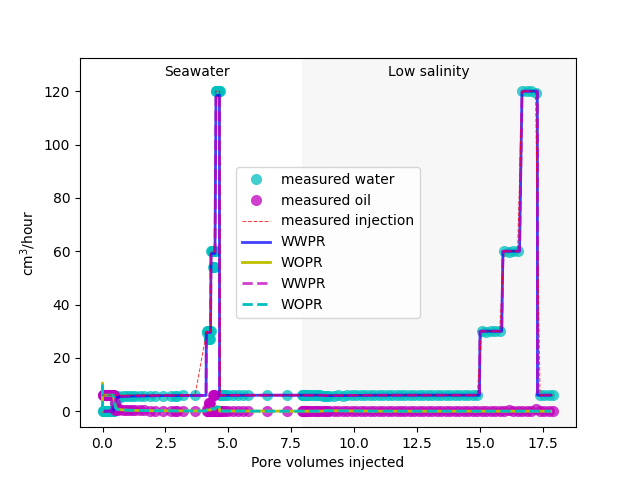

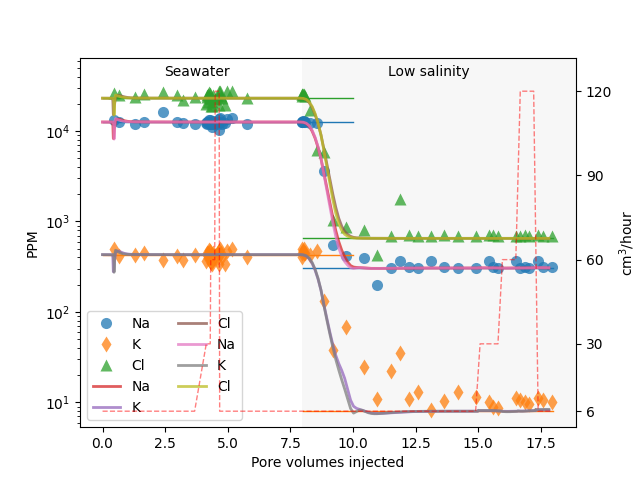

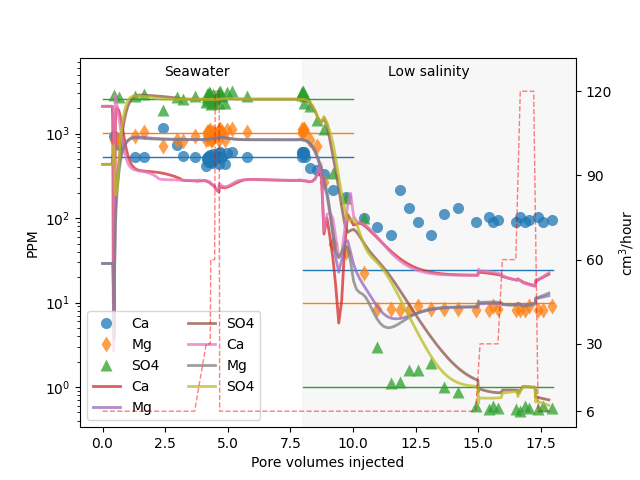

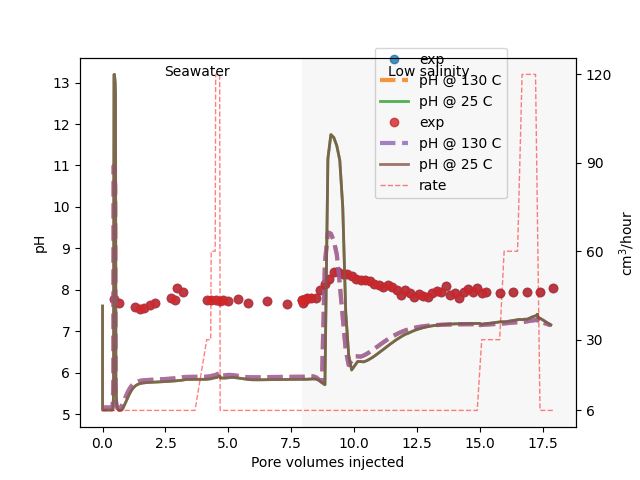

In [ ]:
# Plot experimental data
from itertools import batched
from numpy import isfinite, diff, nan, where, split as npsplit
from pandas import ExcelFile, read_excel
import matplotlib.pyplot as pl
from ior2ecl import IORSim_input
from IORlib.utils import molL2ppm

def total_prod(data):
    tot_prod = data.copy().to_numpy()
    t_change = where(tot_prod==0)[0][-1]
    tot_prod[t_change:] += tot_prod[t_change-1]
    return tot_prod

def shade_low_sal(ax, data):
    # Get time of change to low sal water
    t_lsw = where(data['inj w']==0)[0][-1]
    xlim = ax.get_xlim()
    ax.axvspan(data['PV'][t_lsw], xlim[1], facecolor='k', alpha=0.03)
    ax.set_xlim(xlim)
    ax.text(0.17, 0.95, 'Seawater', transform=ax.transAxes)
    ax.text(0.62, 0.95, 'Low salinity', transform=ax.transAxes)

def adjust_height(*axes, top=0):
    # From: https://stackoverflow.com/questions/29107800/convert-axis-⇔-data-coordinates-systems
    for ax in axes:
        ylim = ax.get_ylim()
        axis_to_data = ax.transAxes + ax.transData.inverted()
        new_ylim = axis_to_data.transform((0, 1+top))
        ax.set_ylim((ylim[0], new_ylim[1]))

def plot_prodrate_sim(data, ax, lines=('b-', 'y-')):
    ax.plot(data.rates.PV, data.rates.water, lines[0], alpha=0.75, lw=2, label='WWPR')
    ax.plot(data.rates.PV, data.rates.oil, lines[1], alpha=1, lw=2, label='WOPR')
    ax.set_ylabel(r'$\mathrm{cm}^3$/hour')


def plot_prodrate_exp(data):
    # Time of change from seawater to low sal water
    t_lsw = where(data['inj w']==0)[0][-1]
    # Split data in ssw and lsw parts
    def split(key):
        return npsplit(data[key].to_numpy(), [t_lsw])
    prod_wat = split('prod w')
    prod_oil = split('prod oil')
    inj_wat = split('inj w')
    rate = split('rate')
    # Get time between measurements from injected water and current rate
    diff_t = [diff(iw)/r[1:] for iw,r in zip(inj_wat, rate)]
    # Calculate rates
    rate_wat = [diff(pw)/dt for pw,dt in zip(prod_wat, diff_t)]
    rate_oil = [diff(po)/dt for po,dt in zip(prod_oil, diff_t)]
    pv = split('PV')
    # Plot measured production rates
    kwargs = dict(lw=2, ms=8, mec='None')
    for i in (0,1):
        pl.plot(pv[i][1:], rate_wat[i], 'o', color='c', alpha=0.75, label='measured water' if i else None, **kwargs)
        pl.plot(pv[i][1:], rate_oil[i], 'o', color='m', alpha=0.75,  label='measured oil' if i else None, **kwargs)
    # Plot measured injection rates
    pl.plot(data['PV'], data['rate'], 'r--', lw=0.75, alpha=0.75, label='measured injection', zorder=10)
    pl.xlabel('Pore volumes injected')
    pl.ylabel(r'$\mathrm{cm}^3$/hour')
    ax = pl.gca()
    shade_low_sal(ax, data)
    adjust_height(ax, top=0.05)

def legend(ignore=None, **kwargs):
    # Legend that combines labels from all axes
    axes = pl.gcf().axes
    lines = [l for ax in axes for l in ax.lines if l.get_label()[0] != '_']
    return axes[0].legend(handles=lines, **kwargs)

def plot_conc_exp(species, data):
    ax1 = pl.gca()
    plot_func = ax1.semilogy
    markers = ('o',  'd', '^',  '>',  'd',  'v')
    for i, specie in enumerate(species):
        m = isfinite(data[specie])
        PV = data['PV'].to_numpy()[m]
        l, = plot_func(PV, data[specie][m], markers[i], mec='None', ms=8, lw=2, alpha=0.75, label=specie)
        col = l.get_color()
        plot_func((0, 10), ones(2)*molL2ppm(specie)*inp_conc['SOLA'][specie], '-', color=col, lw=1, alpha=1)
        plot_func((8, 18), ones(2)*molL2ppm(specie)*inp_conc['SOLB'][specie], '-', color=col, lw=1, alpha=1)
    ax1.set_zorder(1)
    ax1.set_frame_on(False)
    ax1.set_xlabel('Pore volumes injected')
    ax1.set_ylabel('PPM')
    ax2 = plot_rate_exp(data)
    shade_low_sal(ax1, data)
    adjust_height(ax1, ax2, top=0.05)
    #legend()

def plot_conc_sim(species, data):
    ax = pl.gcf().axes[0]
    plot_func = ax.semilogy
    for _, specie in enumerate(species):
        values = molL2ppm(specie)*array(data.species.conc[specie.upper()])
        plot_func(data.species.PV, values, '-', lw=2, alpha=0.75, label=f'{specie}')
    #legend()

def plot_rate_exp(data, ax=None, yticks=True):
    ax = ax or pl.twinx()
    ax.plot(data['PV'], data['rate'], 'r--', lw=1, alpha=0.5, label='rate')
    ax.set_ylabel(r'$\mathrm{cm}^3$/hour')
    if yticks:
        ax.set_yticks((6, 30, 60, 90, 120))
    return ax

def plot_pH(root, data_sim, data_exp, path='.'):
    pl.plot(data_exp['PV'], data_exp['pH'], 'o', lw=3, label='exp', alpha=0.8)
    pH_file = root.parent/path/'pH_data.xls'
    if pH_file.is_file():
        pH_data = read_csv(pH_file)
    else:
        # Calculate pH at 25 deg C
        varnames = ('pH', 'H', 'NA', 'K', 'CA', 'MG', 'CL', 'SO4', 'HCO3')
        unrst = UNRST_file(root.parent/path/root.stem)
        last_block = unrst.celldata((-1,0,0), *varnames, time_res='sec')
        PV = data_sim.species.PV
        pH_130C = last_block.pH[1:]
        pH_25C = pH_at_temp(DataFrame(last_block._asdict()), temp=25, echo='geochem.log')
        pH_data = DataFrame(zip(PV, pH_130C, pH_25C), columns=('PV', 'pH_130C', 'pH_25C'))
        pH_data.to_csv(pH_file, index=False)
        
    pl.plot(pH_data['PV'], pH_data['pH_130C'], '--', lw=3, label='pH @ 130 C', alpha=0.8)
    pl.plot(pH_data['PV'], pH_data['pH_25C'], '-', lw=2, label='pH @ 25 C', alpha=0.8)
    pl.xlabel('Pore volumes injected')
    pl.ylabel('pH')
    

def get_ylimits(ax, cond):
    ymax = 0
    ymin = 9e9
    for line in ax.get_lines():
        y = [y for x,y in line.get_xydata() if cond(x)]
        if y and len(y)>3:
            if (my:=max(y)) > ymax:
                ymax = my
            if (my:=min(y)) < ymin:
                ymin = my
    return ymin, ymax

def zoom_on_seawater():
    cutoff = 9
    ax = pl.gcf().get_axes()[0]
    ax.set_yscale('linear')
    #ax.autoscale()
    xlim = ax.get_xlim()
    ax.set_xlim((xlim[0], cutoff)) 
    ax.set_ylim(get_ylimits(ax, lambda x: x < cutoff))   
    adjust_height(ax, top=0.05)
    #ylim = ax.get_ylim()
    #ax.set_ylim((-1000, ylim[1]))
    for text in ax.texts:
        text.set_alpha(0)
    ax.text(0.4, 0.95, 'Seawater', transform=ax.transAxes)

def zoom_on_lowsal(xlim):
    cutoff = 9
    fig = pl.gcf()
    ax = fig.axes[0]
    ax.set_xlim((cutoff, xlim[1]))
    ax.set_yscale('log')
    ymin, ymax = get_ylimits(ax, lambda x: x > cutoff)
    ax.set_ylim((ymin*0.5, ymax*1.5))
    for text in ax.texts:
        text.set_alpha(0)
    ax.text(0.4, 0.95, 'Low salinity', transform=ax.transAxes)

def zoom_on_start():
    ax = pl.gcf().axes[0]
    ax.set_yscale('linear')
    ax.set_xlim((-0.1, 2))   
    ax.set_ylim((-100, 3100))   


#=============================================================================

xls = ExcelFile(root.with_name('CF6_ions_v2.xlsx'))
ions = read_excel(xls, sheet_name='ions')
ions2 = read_excel(xls, sheet_name='Processed Data 6', skiprows=[0,2])

iorinp = IORSim_input(root)
inp_conc = {sol[0]:dict(batched(sol[1:], 2)) for sol in iorinp.get('solution')}
root = cop/'input/CF6_IORSIM_AH/CF6_IORSIM'
root2 = cop/'input/CF6_IORSIM_NX40/CF6_IORSIM'
path = 'run_dolomite_all_chem'
sim = core_data(root, path=path)
sim2 = core_data(root2)

save_format = 'png'
dpi = 300

pl.close('all')

pl.figure()
plot_prodrate_exp(ions2)
plot_prodrate_sim(sim, pl.gca())
plot_prodrate_sim(sim2, pl.gca(), lines=('m--', 'c--'))
legend()
saveplot(f'plots/plot_lab_prod_rates.'+save_format, dpi=dpi)

pl.figure()
species = ('Na', 'K', 'Cl')
plot_conc_exp(species, ions2)
legend()
saveplot(f'plots/plot_log_lab_Na_K_Cl.'+save_format, dpi=dpi)
plot_conc_sim(species, sim)
plot_conc_sim(species, sim2)
ax = pl.gcf().axes
ax[0].legend(ncols=2, loc='lower left') # species
saveplot(f'plots/plot_log_labsim_Na_K_Cl.'+save_format, dpi=dpi)
# xlim = pl.gca().get_xlim()
# zoom_on_seawater()
# ax[0].legend(ncols=2, bbox_to_anchor=(0.6, 0.5), handletextpad=0.2, columnspacing=0.2) # species
# saveplot(f'plots/plot_zoom_ssw_labsim_Na_K_Cl.'+save_format, dpi=dpi)
# zoom_on_lowsal(xlim)
# ax[0].legend(ncols=2, loc='center') # species
# #ax[1].legend(bbox_to_anchor=(0.65, 0.1), frameon=False) # rate
# saveplot(f'plots/plot_zoom_lsw_labsim_Na_K_Cl.'+save_format, dpi=dpi)

pl.figure()
species = ('Ca', 'Mg', 'SO4')
plot_conc_exp(species, ions2)
legend()
saveplot(f'plots/plot_log_lab_Ca_Mg_SO4.'+save_format, dpi=dpi)
plot_conc_sim(species, sim)
plot_conc_sim(species, sim2)
ax = pl.gcf().axes
ax[0].legend(ncols=2, loc='lower left') # species
#ax[1].legend(bbox_to_anchor=(0.8, 0.8)) # rate
saveplot(f'plots/plot_log_labsim_Ca_Mg_SO4.'+save_format, dpi=dpi)
# zoom_on_start()
# ax[0].legend(ncols=2, bbox_to_anchor=(0.6, 0.5), handletextpad=0.2, columnspacing=0.2) # species
# saveplot(f'plots/plot_zoom_start_labsim_Ca_Mg_SO4.'+save_format, dpi=dpi)
# xlim = pl.gca().get_xlim()
# zoom_on_seawater()
# ax[0].legend(ncols=2, bbox_to_anchor=(0.6, 0.5), handletextpad=0.2, columnspacing=0.2) # species
# saveplot(f'plots/plot_zoom_ssw_labsim_Ca_Mg_SO4.'+save_format, dpi=dpi)
# zoom_on_lowsal(xlim)
# ax[0].legend(ncols=2, bbox_to_anchor=(0.55, 0.32)) # species
# #ax[1].legend(bbox_to_anchor=(0.45, 0.15), frameon=False) # rate
# saveplot(f'plots/plot_zoom_lsw_labsim_Ca_Mg_SO4.'+save_format, dpi=dpi)


pl.figure()
plot_pH(root, sim, ions2, path=path)
#plot_pH(root, sim2, ions2, path=path)
plot_rate_exp(ions2)
shade_low_sal(pl.gca(), ions2)
legend(bbox_to_anchor=(0.58, 0.6))
saveplot(f'plots/pH.'+save_format, dpi=dpi)



/home/shared/owner/CoP_files/input/CF6_IORSIM_NX40/CF6_IORSIM.UNRST


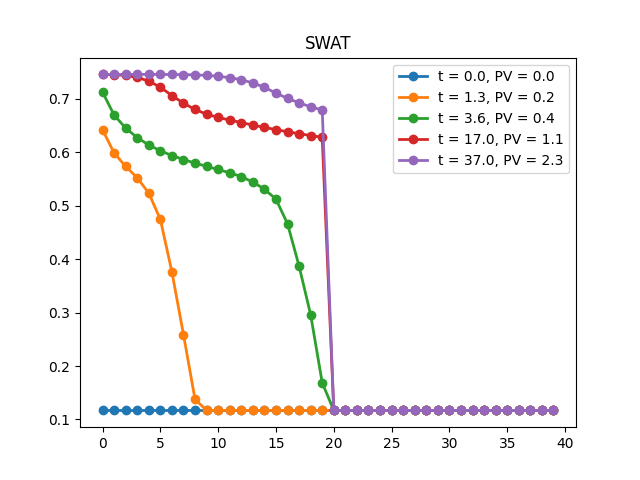

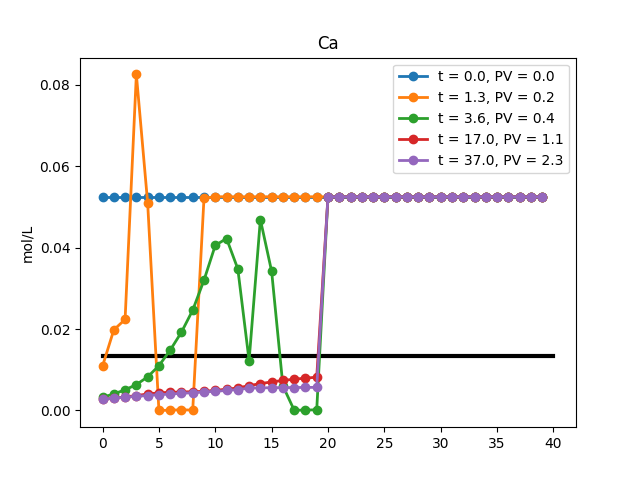

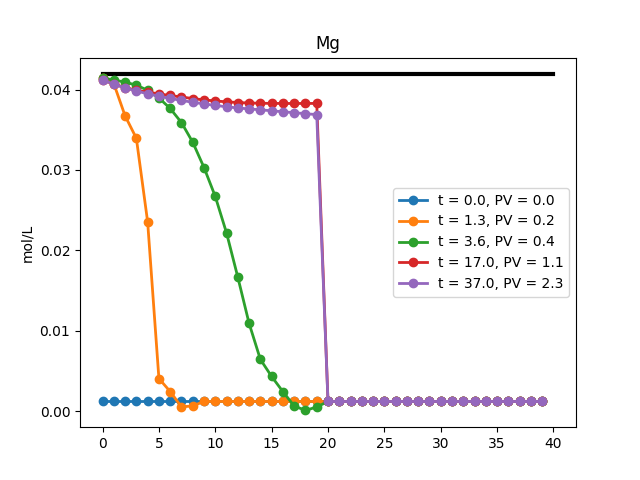

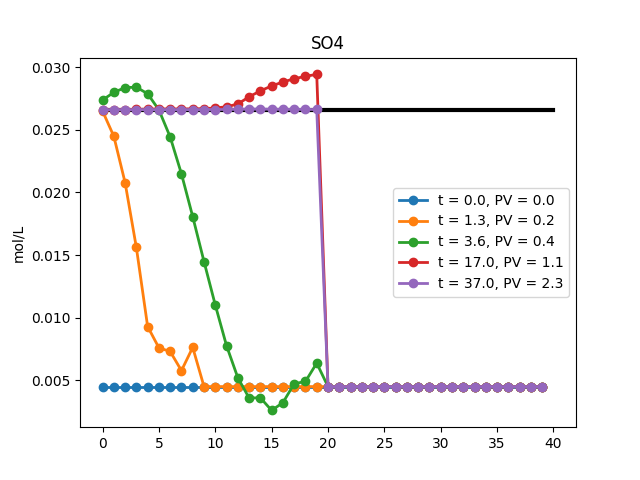

In [12]:
#unrst = UNRST_file(root.parent/folder/root.stem)
root = cop/'input/CF6_IORSIM_NX40/CF6_IORSIM'
unrst = UNRST_file(root)
names = ('NA', 'K', 'CA', 'MG', 'CL', 'SO4', 'HCO3', 'SWAT', 'SOIL')
conc = dict(zip(names, zip(*unrst.blockdata(*names))))
print(unrst.path)
#for i in range(3):
#    print(i)
#    print(''.join([f'{k} {v[i][-1]}\n' for k,v in conc.items()]))

days = list(unrst.days(resolution='sec'))
#hours = days*24
N = len(conc['CA'][0])

def plot_cells(specie, i=60):
    pl.figure()
    pl.title(specie)
    pl.plot((0, days[:i][-1]), inp_solution['SOLA'][specie]*ones(2), lw=2)
    for j in range(0,20,5):
        pl.plot(days[:i], [c[j] for c in conc[specie.upper()][:i]], 'o-', lw=2, label=str(j))
    pl.legend()
    pl.show()

def plot_along(specie):
    plot_func = pl.plot
    pl.figure()
    pl.title(specie)
    try:
        plot_func((0, N), inp_solution['SOLA'][specie]*ones(2), 'k-', lw=3)
        pl.ylabel('mol/L')
    except KeyError:
        pass
    for t in range(0,100,20):
        plot_func(conc[specie.upper()][t][:], 'o-', lw=2, alpha=1, label=f't = {days[t]*24:.1f}, PV = {sim.species.PV[t]:.1f}')
    pl.legend()
    pl.show()

pl.close('all')
for var in ('SWAT','Ca', 'Mg', 'SO4'):
    #plot_cells(specie)
    plot_along(var)

